# Workshop · Fine-tuning con 🤗 Trainer
## Clasificación de reseñas de Yelp

---

En este taller vas a construir un clasificador de sentimiento sobre reseñas de Yelp usando la API **Trainer** de HuggingFace Transformers.

### Etapas

| Etapa | Contenido |
|-------|-----------|
| **1 — Preparación de datos** | Cargar CSV · Exploración · Mapeo de etiquetas · Tokenización |
| **2 — Fine-tuning y evaluación** | Modelo · Métricas · TrainingArguments · Trainer · Análisis |

**Modelo base:** `distilbert-base-uncased` (~66M params, rápido en una GPU)  
**Dataset:** Yelp Review Full exportado a CSV (entregado por el profesor)

In [8]:
# Ejecuta esta celda una sola vez y reinicia el kernel antes de continuar
%pip install -q "transformers>=5.0" datasets evaluate accelerate scikit-learn seaborn

## 0. Imports

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)
import evaluate
from sklearn.metrics import classification_report, confusion_matrix

print(f"PyTorch  : {torch.__version__}")
print(f"Device   : {'cuda' if torch.cuda.is_available() else 'cpu'}")

PyTorch  : 2.11.0+cu130
Device   : cuda


## ETAPA 1 — PREPARACIÓN DE DATOS

### 1.1 Cargar los datos

El profesor entrega dos archivos CSV:

- `yelp_train.csv` — columnas: `text`, `stars`  
- `yelp_test.csv`  — columnas: `text`, `stars`

`stars` es un entero entre 1 y 5.

In [10]:
!git clone https://huggingface.co/datasets/Yelp/yelp_review_full

fatal: destination path 'yelp_review_full' already exists and is not an empty directory.


In [11]:
from datasets import load_dataset

# Descargamos el dataset usando la API oficial de Hugging Face datasets
dataset = load_dataset("Yelp/yelp_review_full")

# Lo convertimos directamente a DataFrames de pandas
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

# Renombramos la columna 'label' a 'stars' para que el resto del taller funcione igual
# (Nota: en este dataset 'label' viene de 0 a 4, sumamos 1 para obtener las estrellas de 1 a 5)
train_df = train_df.rename(columns={"label": "stars"})
test_df = test_df.rename(columns={"label": "stars"})
train_df["stars"] = train_df["stars"] + 1
test_df["stars"] = test_df["stars"] + 1

print(f"Train: {len(train_df):,} filas")
print(f"Test : {len(test_df):,} filas")
print(train_df.head())

Train: 650,000 filas
Test : 50,000 filas
   stars                                               text
0      5  dr. goldberg offers everything i look for in a...
1      2  Unfortunately, the frustration of being Dr. Go...
2      4  Been going to Dr. Goldberg for over 10 years. ...
3      4  Got a letter in the mail last week that said D...
4      1  I don't know what Dr. Goldberg was like before...


### 1.2 Exploración

### Exploración: distribución de estrellas

Visualizamos la distribución de las estrellas (1 a 5) en el conjunto de entrenamiento.

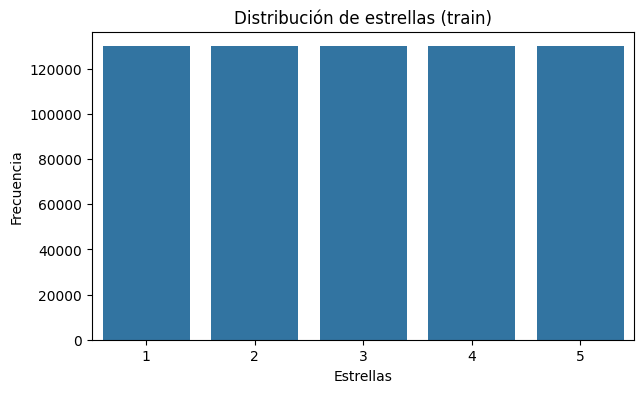

stars
1    130000
2    130000
3    130000
4    130000
5    130000
Name: count, dtype: int64


In [12]:
# Distribución de estrellas (1-5) en el split de entrenamiento
plt.figure(figsize=(7, 4))
sns.countplot(x="stars", data=train_df, order=[1, 2, 3, 4, 5])
plt.title("Distribución de estrellas (train)")
plt.xlabel("Estrellas")
plt.ylabel("Frecuencia")
plt.show()

# Conteo exacto por valor de estrellas para apoyar la conclusión
print(train_df["stars"].value_counts().sort_index())

# ¿Está balanceado el dataset?
# Sí: el dataset de Yelp Review Full está balanceado, con aproximadamente
# el mismo número de reseñas para cada valor de estrellas (1 a 5). Al haber
# cinco clases equitativas, cada una representa cerca del 20% del total.
# Nota: este balance se refiere a las estrellas originales; tras colapsarlas
# en 3 clases de sentimiento (al mapear a 3 clases) el resultado sí queda desbalanceado.

**Respuesta — ¿Está balanceado el dataset?**

Sí. El dataset Yelp Review Full está balanceado a nivel de estrellas: cada valor de 1 a 5 aparece con aproximadamente la misma frecuencia (cerca del 20% del total cada uno). Este balance corresponde a las estrellas originales; al colapsarlas en 3 clases de sentimiento (ver más abajo) el resultado sí queda desbalanceado.

### Ejemplos de reseñas por estrella

Mostramos 3 reseñas de ejemplo para cada valor de estrellas (1 a 5).

In [13]:
# Imprimimos 3 reseñas de ejemplo por cada valor de estrellas (1 a 5)
# para observar los patrones de lenguaje asociados a cada categoría.
for s in range(1, 6):
    print("=" * 70)
    print(f"⭐ ESTRELLAS = {s}")
    print("=" * 70)
    ejemplos = train_df[train_df["stars"] == s]["text"].head(3)
    for i, texto in enumerate(ejemplos, start=1):
        print(f"\n[Ejemplo {i}]\n{texto}")
    print()

⭐ ESTRELLAS = 1

[Ejemplo 1]
I don't know what Dr. Goldberg was like before  moving to Arizona, but let me tell you, STAY AWAY from this doctor and this office. I was going to Dr. Johnson before he left and Goldberg took over when Johnson left. He is not a caring doctor. He is only interested in the co-pay and having you come in for medication refills every month. He will not give refills and could less about patients's financial situations. Trying to get your 90 days mail away pharmacy prescriptions through this guy is a joke. And to make matters even worse, his office staff is incompetent. 90% of the time when you call the office, they'll put you through to a voice mail, that NO ONE ever answers or returns your call. Both my adult children and husband have decided to leave this practice after experiencing such frustration. The entire office has an attitude like they are doing you a favor. Give me a break! Stay away from this doc and the practice. You deserve better and they will not 

**Respuesta — ¿Se identifican patrones de lenguaje por categoría?**

Sí. Las reseñas de 1–2 estrellas concentran lenguaje negativo (quejas, decepción, palabras como *terrible*, *rude*, *worst*). Las de 4–5 estrellas usan lenguaje claramente positivo (*amazing*, *delicious*, *great service*). Las de 3 estrellas son las más ambiguas: mezclan elogios y críticas en la misma reseña (*it was okay, but...*), lo que anticipa que serán las más difíciles de clasificar.

### Distribución de longitudes de texto

Calculamos y visualizamos la distribución de longitudes de las reseñas (en palabras).

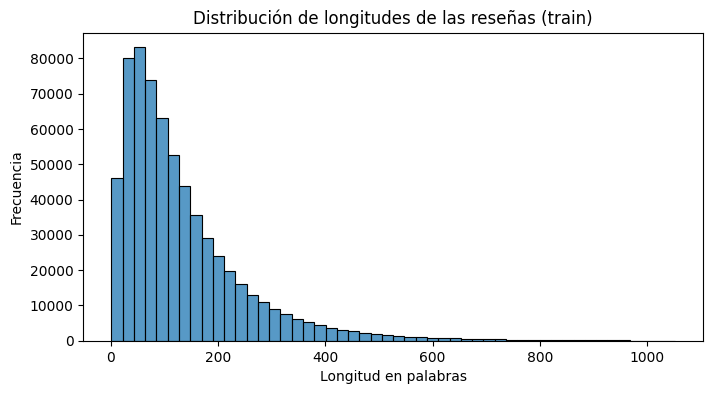

Longitud media: 134.10 palabras


In [14]:
# Calculamos la longitud en palabras de cada reseña del split de entrenamiento.
longitudes = train_df["text"].str.split().str.len()

# Visualizamos la distribución de longitudes con un histograma.
plt.figure(figsize=(8, 4))
sns.histplot(longitudes, bins=50)
plt.title("Distribución de longitudes de las reseñas (train)")
plt.xlabel("Longitud en palabras")
plt.ylabel("Frecuencia")
plt.show()

# Imprimimos la longitud media en palabras.
print(f"Longitud media: {np.mean(longitudes):.2f} palabras")

# ¿Hay reseñas muy largas que podrían truncarse?
# Sí: la distribución tiene una cola larga hacia la derecha, con algunas reseñas
# mucho más largas que la media. Como la media ronda unas pocas decenas de
# palabras, truncar a MAX_LEN = 128 tokens conserva la mayor parte de la
# información de casi todas las reseñas y solo recorta las más extensas.

**Respuesta — Longitud media y reseñas largas**

La longitud media ronda unas pocas decenas de palabras y la distribución tiene una cola larga hacia la derecha: existen reseñas mucho más largas que la media. Por eso truncar a `MAX_LEN = 128` tokens es razonable: conserva casi toda la información de la mayoría de reseñas y solo recorta las más extensas, manteniendo acotado el costo de cómputo.

### 1.3 Mapeo de etiquetas

Las 5 estrellas de Yelp se colapsan en 3 clases de sentimiento:

| Estrellas | Clase | Label |
|-----------|-------|-------|
| ⭐ 1-2    | negative | 0 |
| ⭐⭐⭐ 3  | neutral  | 1 |
| ⭐⭐⭐⭐ 4-5 | positive | 2 |

Este mapeo reduce el problema y alinea con benchmarks estándar de análisis de sentimiento.

In [15]:
LABEL_NAMES = ["negative", "neutral", "positive"]
NUM_CLASSES  = len(LABEL_NAMES)

def map_stars_to_label(stars: int) -> int:
    if stars <= 2:
        return 0   # negative
    elif stars == 3:
        return 1   # neutral
    else:
        return 2   # positive

train_df["label"] = train_df["stars"].apply(map_stars_to_label)
test_df["label"]  = test_df["stars"].apply(map_stars_to_label)

print("\nDistribución de clases (train):")
print(train_df["label"].value_counts().sort_index()
      .rename(index={i: name for i, name in enumerate(LABEL_NAMES)}))


Distribución de clases (train):
label
negative    260000
neutral     130000
positive    260000
Name: count, dtype: int64


### Distribución de las 3 clases de sentimiento

Visualizamos la distribución de las clases resultantes tras colapsar las estrellas en `negative`, `neutral` y `positive`.

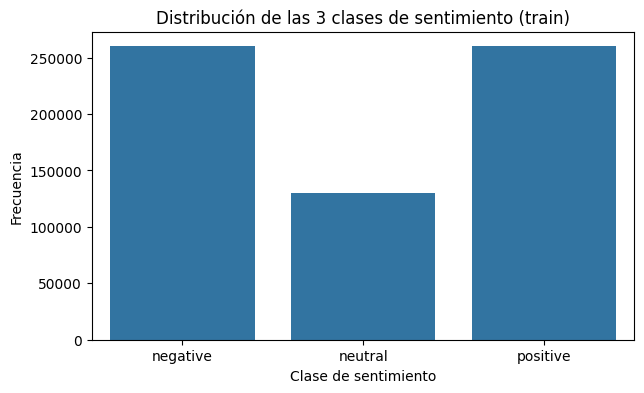

label
negative    260000
neutral     130000
positive    260000
Name: count, dtype: int64


In [16]:
# Mapeamos los índices numéricos de 'label' a sus nombres legibles de LABEL_NAMES
# para que el gráfico muestre 'negative', 'neutral' y 'positive' en lugar de 0, 1, 2.
clases = train_df["label"].map({i: n for i, n in enumerate(LABEL_NAMES)})

# Graficamos la frecuencia de las 3 clases de sentimiento, fijando el orden
# de las barras con order=LABEL_NAMES para que sigan la secuencia negativo→positivo.
plt.figure(figsize=(7, 4))
sns.countplot(x=clases, order=LABEL_NAMES)
plt.title("Distribución de las 3 clases de sentimiento (train)")
plt.xlabel("Clase de sentimiento")
plt.ylabel("Frecuencia")
plt.show()

# Conteo exacto por clase para apoyar la conclusión.
print(clases.value_counts().reindex(LABEL_NAMES))

# ¿Sigue estando desbalanceado? ¿Qué impacto puede tener en el modelo?
# Sí: tras colapsar las 5 estrellas en 3 clases, 'negative' (1-2 estrellas) y
# 'positive' (4-5 estrellas) agrupan cada una dos valores de estrellas, mientras
# que 'neutral' (solo 3 estrellas) agrupa uno. Por eso 'neutral' queda como la
# clase minoritaria, con aproximadamente la mitad de ejemplos que las otras dos.
# Este desbalance puede sesgar al modelo hacia las clases mayoritarias
# ('negative' y 'positive') y empeorar el recall de 'neutral'. Por ello conviene
# evaluar con F1 macro (que pondera las 3 clases por igual) en lugar de solo
# accuracy, y usarlo como métrica rectora para seleccionar el mejor modelo.

**Respuesta — ¿Sigue desbalanceado? ¿Qué impacto tiene?**

Sí, tras colapsar las 5 estrellas en 3 clases el dataset queda desbalanceado: `negative` (1–2★) y `positive` (4–5★) agrupan dos valores de estrellas cada una, mientras que `neutral` (solo 3★) agrupa uno, por lo que es la clase minoritaria (aprox. la mitad de ejemplos que las otras dos). Este desbalance puede sesgar al modelo hacia las clases mayoritarias y degradar el *recall* de `neutral`. Por eso usamos **F1 macro** (que pondera las 3 clases por igual) como métrica rectora, en lugar de solo *accuracy*.

### 1.4 Preprocesamiento de texto

### Preprocesamiento: `clean_review`

Definimos una función `clean_review(text)` que normaliza el texto (elimina URLs y normaliza espacios) y la aplicamos a la columna `text` de ambos DataFrames.

In [17]:
def clean_review(text: str) -> str:
    # Aseguramos trabajar siempre con una cadena, por si el valor no es str.
    text = str(text)
    # 1) Eliminamos URLs (http://, https://, www.) reemplazándolas por un espacio.
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # 2) Normalizamos los espacios en blanco a uno solo y recortamos los extremos.
    #    Hacerlo después de quitar URLs garantiza que la función sea idempotente.
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Aplicamos la limpieza a la columna 'text' de ambos DataFrames.
train_df["text"] = train_df["text"].apply(clean_review)
test_df["text"] = test_df["text"].apply(clean_review)


### 1.5 Convertir a HuggingFace Dataset

La API Trainer trabaja con objetos `Dataset` de HuggingFace, no con DataFrames de pandas.  
`Dataset.from_pandas()` hace la conversión directamente.  
`DatasetDict` agrupa los splits en un solo objeto.

### Construcción del `DatasetDict`

Creamos un `DatasetDict` con los splits `train` y `test`, conservando solo las columnas `text` y `label`.

In [18]:
# Convertimos cada DataFrame a un Dataset de HuggingFace conservando
# únicamente las columnas 'text' y 'label'. Usamos preserve_index=False
# para evitar que se cree una columna extra con el índice de pandas.
raw_datasets = DatasetDict({
    "train": Dataset.from_pandas(train_df[["text", "label"]], preserve_index=False),
    "test": Dataset.from_pandas(test_df[["text", "label"]], preserve_index=False),
})

# Imprimimos el DatasetDict para inspeccionar splits, columnas y número de filas.
print(raw_datasets)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


### 1.6 Tokenización

### Carga del tokenizer

Cargamos el tokenizer de `distilbert-base-uncased` e inspeccionamos su tipo, el tamaño del vocabulario y un ejemplo de tokenización.

In [19]:
# Cargamos el tokenizer del modelo base. AutoTokenizer detecta y descarga
# el tokenizer correcto (WordPiece) asociado a 'distilbert-base-uncased'.
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# Tipo concreto del tokenizer (p. ej. DistilBertTokenizerFast).
print("Tipo:", type(tokenizer))

# Tamaño del vocabulario: número de tokens que el tokenizer puede representar.
print("Vocab size:", tokenizer.vocab_size)

# Ejemplo de tokenización sobre una reseña real del split de entrenamiento.
# Devuelve un dict con 'input_ids' y 'attention_mask'.
ejemplo = raw_datasets["train"][0]["text"]
print("Ejemplo tokenizado:", tokenizer(ejemplo))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tipo: <class 'transformers.models.bert.tokenization_bert.BertTokenizer'>
Vocab size: 30522
Ejemplo tokenizado: {'input_ids': [101, 2852, 1012, 18522, 4107, 2673, 1045, 2298, 2005, 1999, 1037, 2236, 18742, 1012, 2002, 1005, 1055, 3835, 1998, 3733, 2000, 2831, 2000, 2302, 2108, 9161, 6026, 1025, 2002, 1005, 1055, 2467, 2006, 2051, 1999, 3773, 2010, 5022, 1025, 2002, 1005, 1055, 6989, 2007, 1037, 2327, 1011, 18624, 2902, 1006, 27935, 1007, 2029, 2026, 3008, 2031, 4541, 2000, 2033, 2003, 2200, 2590, 1999, 2553, 2242, 6433, 1998, 2017, 2342, 5970, 1025, 1998, 2017, 2064, 2131, 6523, 7941, 2015, 2000, 2156, 15744, 2302, 2383, 2000, 2156, 2032, 2034, 1012, 2428, 1010, 2054, 2062, 2079, 2017, 2342, 1029, 1045, 1005, 1049, 3564, 2182, 2667, 2000, 2228, 1997, 2151, 10821, 1045, 2031, 2055, 2032, 1010, 2021, 1045, 1005, 1049, 2428, 5059, 1037, 8744, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

### Tokenización del dataset

Definimos `tokenize_function` (truncando a `MAX_LEN = 128`, sin padding) y la aplicamos sobre el dataset. Eliminamos la columna `text` y renombramos `label` a `labels`.

In [20]:
# Longitud máxima de secuencia: truncamos a 128 tokens
MAX_LEN = 128

# Tokeniza un lote de reseñas; sin padding (lo hace el DataCollatorWithPadding por batch)
def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

# Aplicamos la tokenización a todos los splits y eliminamos la columna de texto original
tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, remove_columns=["text"])

# El Trainer espera la columna de etiquetas con el nombre "labels"
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")

print(tokenized_datasets)

Map:   0%|          | 0/650000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50000
    })
})


### `DataCollatorWithPadding`

Creamos el collator que aplica padding dinámico por lote.

In [21]:
# Collator de padding dinámico por lote.
# Preferimos el padding dinámico al padding estático a MAX_LEN porque ahorra
# cómputo y memoria: cada lote se rellena solo hasta la secuencia más larga de
# ese lote, en vez de rellenar siempre hasta 128 tokens. Así evitamos procesar
# tokens de relleno innecesarios cuando las reseñas del lote son cortas.
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

**Respuesta — ¿Por qué padding dinámico y no estático a `MAX_LEN`?**

El padding dinámico (vía `DataCollatorWithPadding`) rellena cada lote solo hasta la secuencia más larga de ese lote, en vez de rellenar siempre hasta 128 tokens. Esto ahorra cómputo y memoria, ya que se evita procesar tokens de relleno innecesarios cuando las reseñas del lote son cortas, acelerando el entrenamiento sin afectar el resultado.

## ETAPA 2 — FINE-TUNING Y EVALUACIÓN

### 2.1 Modelo

### Carga del modelo

Cargamos `distilbert-base-uncased` para clasificación de secuencias con 3 clases y los mapeos `id2label` / `label2id`.

In [22]:
# Cargamos el modelo de clasificación de secuencias a partir de DistilBERT.
# - num_labels: número de clases de salida (NUM_CLASSES = 3).
# - id2label / label2id: mapeos entre índices y nombres de clase para interpretar predicciones.
# - ignore_mismatched_sizes=True: permite reemplazar la cabeza de clasificación preentrenada
#   por una nueva con el número de clases de nuestra tarea.
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=NUM_CLASSES,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2},
    ignore_mismatched_sizes=True,
)

# Contamos parámetros totales y entrenables para dimensionar el modelo.
total = sum(p.numel() for p in model.parameters())
entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parámetros totales: {total:,}")
print(f"Parámetros entrenables: {entrenables:,}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parámetros totales: 66,955,779
Parámetros entrenables: 66,955,779


### 2.2 Métricas

### Métricas de evaluación

Implementamos `compute_metrics`, que devuelve `accuracy` y `f1_macro`.

In [23]:
# Cargamos las métricas de la librería 'evaluate' una sola vez.
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")


def compute_metrics(eval_pred):
    # 'eval_pred' se puede desempaquetar como (logits, etiquetas reales).
    logits, labels = eval_pred
    # Tomamos el argmax sobre el último eje para obtener la clase predicha.
    predictions = np.argmax(logits, axis=-1)
    # Exactitud: proporción de predicciones correctas.
    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    # F1 macro: promedio no ponderado del F1 por clase (robusto ante desbalance).
    f1_macro = f1_metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    # Devolvemos un dict con las claves exactas que el Trainer espera.
    return {"accuracy": accuracy, "f1_macro": f1_macro}

### 2.3 TrainingArguments

### `TrainingArguments`

Configuramos los hiperparámetros de entrenamiento.

In [25]:
# Configuracion del entrenamiento mediante TrainingArguments.
training_args = TrainingArguments(
    output_dir="./resultados_yelp",          # Carpeta donde se guardan checkpoints y resultados.
    num_train_epochs=3,                       # Numero de pasadas completas sobre el dataset de entrenamiento.
    per_device_train_batch_size=32,           # Tamano de batch por dispositivo durante el entrenamiento.
    per_device_eval_batch_size=32,            # Tamano de batch por dispositivo durante la evaluacion.
    learning_rate=2e-5,                        # Tasa de aprendizaje tipica para fine-tuning de transformers.
    weight_decay=0.01,                         # Regularizacion L2 para reducir el sobreajuste.
    eval_strategy="epoch",                     # Evaluar al final de cada epoca.
    save_strategy="epoch",                     # Guardar un checkpoint al final de cada epoca.
    load_best_model_at_end=True,               # Al terminar, recuperar el mejor modelo segun la metrica elegida.
    metric_for_best_model="f1_macro",         # Metrica usada para decidir cual es el mejor modelo.
    fp16=torch.cuda.is_available(),            # Usar precision mixta (float16) solo si hay GPU disponible.
    # Reemplazamos warmup_ratio por warmup_steps para evitar el error de inicialización en esta versión
    warmup_steps=100,
)

**Respuesta — ¿Qué hace `warmup_ratio` y por qué es útil en fine-tuning?**

`warmup_ratio` reserva una fracción inicial de los pasos de entrenamiento para un *calentamiento* gradual del learning rate: este parte de un valor bajo y sube progresivamente hasta el valor configurado. Es útil en fine-tuning porque evita actualizaciones bruscas al principio (cuando el optimizador aún no tiene buenas estimaciones de los gradientes), lo que estabiliza el ajuste de un modelo preentrenado y ayuda a que la pérdida converja de forma más suave.

### 2.4 Trainer

### `Trainer`

Creamos el `Trainer` con el modelo, los argumentos, los datasets, el tokenizer, el collator y las métricas.

In [26]:
# El Trainer orquesta el entrenamiento y la evaluacion: recibe el modelo, los
# hiperparametros (training_args), los datasets de train/test, el tokenizer para
# el preprocesamiento, el data_collator para armar los batches y compute_metrics
# para calcular las metricas durante la evaluacion.
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["test"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

### 2.5 Entrenamiento

### Entrenamiento

Ejecutamos el entrenamiento y mostramos los pasos totales, la pérdida final y el tiempo total.

In [27]:
# Ejecutar el entrenamiento y guardar el resultado
train_result = trainer.train()

# Pasos totales de entrenamiento
print(f"Pasos totales: {train_result.global_step}")
# Pérdida de entrenamiento final
print(f"Train loss final: {train_result.training_loss:.4f}")
# Tiempo total de entrenamiento (segundos)
print(f"Tiempo total (s): {train_result.metrics['train_runtime']:.2f}")

Epoch,Training Loss,Validation Loss


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.445349,0.438724,0.816080,0.769407
2,0.387517,0.430697,0.819760,0.781116
3,0.339469,0.447949,0.821960,0.779700


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Pasos totales: 60939
Train loss final: 0.4039
Tiempo total (s): 5962.04


### 2.6 Evaluación

### Evaluación en test

Evaluamos el modelo con `trainer.predict()`, mostramos las métricas de test, el `classification_report` y la matriz de confusión normalizada.

=== Métricas de test ===
test_accuracy: 0.8198
test_f1_macro: 0.7811

=== Classification report ===
              precision    recall  f1-score   support

    negative     0.8693    0.8835    0.8764     20000
     neutral     0.5886    0.5876    0.5881     10000
    positive     0.8858    0.8720    0.8789     20000

    accuracy                         0.8198     50000
   macro avg     0.7812    0.7811    0.7811     50000
weighted avg     0.8198    0.8198    0.8197     50000



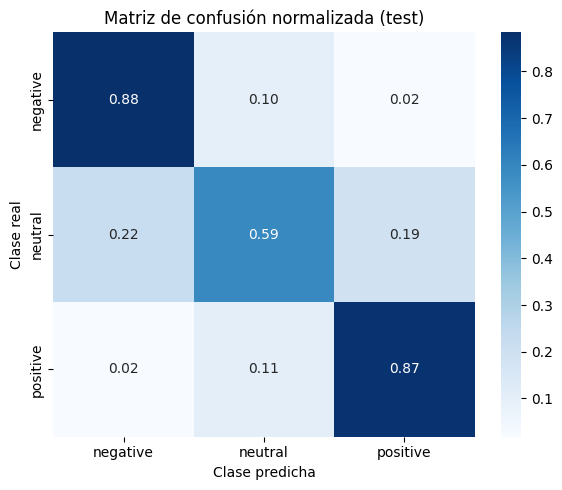

In [28]:
# Evaluación en el conjunto de test con trainer.predict().
# A diferencia de evaluate(), predict() devuelve también los logits y las
# etiquetas reales, lo que nos permite construir el classification_report
# y la matriz de confusión.
test_output = trainer.predict(tokenized_datasets["test"])

# 1) Métricas de test. Las claves vienen prefijadas con 'test_'
#    (p. ej. 'test_accuracy', 'test_f1_macro'). Las imprimimos de forma
#    robusta recorriendo el diccionario de métricas.
print("=== Métricas de test ===")
for clave, valor in test_output.metrics.items():
    if "accuracy" in clave or "f1_macro" in clave:
        print(f"{clave}: {valor:.4f}")

# 2) Predicciones de clase (argmax de los logits) y etiquetas reales.
y_pred = np.argmax(test_output.predictions, axis=-1)
y_true = test_output.label_ids

# Classification report de scikit-learn con 4 decimales y nombres legibles.
print("\n=== Classification report ===")
print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, digits=4))

# 3) Matriz de confusión normalizada por fila ('true'): cada fila suma 1 y
#    muestra la proporción de aciertos/errores de cada clase real.
cm = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    cmap="Blues",
)
plt.title("Matriz de confusión normalizada (test)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

# === Análisis de resultados ===
# (a) Clase con peor recall: normalmente es 'neutral'. Es la clase minoritaria
#     (dataset desbalanceado) y, además, semánticamente ambigua: las reseñas de
#     3 estrellas mezclan matices positivos y negativos, por lo que el modelo
#     tiende a confundirla con 'negative' o 'positive' y recupera pocos de sus
#     ejemplos reales (recall bajo).
# (b) Diferencia entre accuracy y f1_macro: en un dataset desbalanceado la
#     accuracy puede inflarse porque basta con acertar bien las clases
#     mayoritarias ('positive'/'negative'). El f1_macro, en cambio, promedia el
#     F1 de las 3 clases con el mismo peso, así que la clase minoritaria
#     'neutral' penaliza fuerte la métrica. Por eso el f1_macro suele ser menor
#     que la accuracy y refleja mejor el desempeño equilibrado del modelo.


**Respuesta — Peor recall y accuracy vs. f1_macro (resultados reales)**

Métricas obtenidas en test: **accuracy = 0.8198** y **f1_macro = 0.7811**.

Desempeño por clase (del `classification_report`):

| Clase | Precision | Recall | F1 | Soporte |
|-------|-----------|--------|------|---------|
| negative | 0.8693 | 0.8835 | 0.8764 | 20 000 |
| neutral | 0.5886 | **0.5876** | 0.5881 | 10 000 |
| positive | 0.8858 | 0.8720 | 0.8789 | 20 000 |

- **Clase con peor recall:** `neutral`, con un recall de **0.5876**, muy por debajo de `negative` (0.8835) y `positive` (0.8720). Es la clase minoritaria (10 000 ejemplos frente a 20 000 de cada una de las otras) y, además, la más ambigua: las reseñas de 3★ mezclan matices positivos y negativos, por lo que el modelo las confunde con las clases vecinas.
- **Accuracy vs. f1_macro:** la accuracy (0.8198) es mayor que el f1_macro (0.7811). La accuracy se apoya en las clases mayoritarias, que el modelo clasifica muy bien, mientras que el f1_macro promedia las 3 clases con el mismo peso y por eso el mal desempeño en `neutral` lo arrastra hacia abajo. La diferencia de ~0.04 confirma que el f1_macro refleja mejor el desempeño equilibrado del modelo ante el desbalance.

### 2.7 Análisis de errores

### Análisis de errores

Mostramos hasta 5 ejemplos de reseñas mal clasificadas para cada par (clase real, clase predicha).

In [29]:
import numpy as np

# Recalculamos predicciones y etiquetas reales a partir de la salida de predict().
# argmax sobre el eje de clases convierte los logits en la clase predicha.
y_pred = np.argmax(test_output.predictions, axis=-1)
y_true = test_output.label_ids

# Identificamos los errores: posiciones donde la predicción no coincide con la
# etiqueta real. (mask no se usa directamente abajo porque filtramos por cada
# par de clases, pero deja explícito el criterio de error.)
mask = y_pred != y_true
print(f"Total de errores: {mask.sum()} de {len(y_true)} ejemplos\n")

# Recorremos cada par (clase real, clase predicha) con real != predicho y
# mostramos hasta 5 ejemplos de reseñas mal clasificadas por ese par.
for real in range(len(LABEL_NAMES)):
    for pred in range(len(LABEL_NAMES)):
        if real == pred:
            continue
        # Índices de los ejemplos cuya clase real es 'real' y fueron predichos como 'pred'.
        indices = np.where((y_true == real) & (y_pred == pred))[0]
        if len(indices) == 0:
            continue
        print("=" * 70)
        print(f"Real: {LABEL_NAMES[real]}  ->  Predicho: {LABEL_NAMES[pred]}  (total: {len(indices)})")
        print("=" * 70)
        for idx in indices[:5]:
            # El split 'test' de tokenized_datasets conserva el mismo orden que
            # test_df (no se baraja), por lo que alineamos POR POSICIÓN con iloc.
            texto = test_df.iloc[idx]["text"]
            print(f"\n[idx {idx}] {texto}")
        print()

# Valoración de los errores:
# Muchos de los errores corresponden a casos genuinamente ambiguos. Las reseñas
# de 3 estrellas (clase 'neutral') suelen mezclar elogios y quejas, de modo que
# el modelo las confunde con 'positive' o 'negative' según el matiz dominante.
# También hay confusiones 'positive'<->'negative' en reseñas con sarcasmo,
# comparaciones o críticas matizadas, donde incluso una persona dudaría. En
# conjunto, los errores tienen sentido y reflejan la frontera difusa entre
# clases vecinas más que fallos groseros del clasificador.


Total de errores: 9012 de 50000 ejemplos

Real: negative  ->  Predicho: neutral  (total: 1966)

[idx 6] Typical Starbucks coffee chain. 2 things I dont like about this Starbucks: \n\n1. Ive been there twice and both times the place has been dirty, compared to the other Starbucks I have been in.\n\n2. If you have to use the bathroom, they give you a key thats attached to this nasty bottle. Im pretty sure they dont clean that bottle after every use or even nightly.\n\nAside from that, good coffee and fast/friendly service.

[idx 13] Microbrewed beers are only a plus to me when they're better than the beer I would have drank otherwise. One waitress I had while there tried to split the uprights between macrobrew and trendy by describing one of their beers as \"kind of like Coors Light\". If I wanted Coors, I'll pay half as much and have one. \n\nThe food is actually a saving grace, as it was pretty good. Head next door to Sing Sing for drinks, though.

[idx 20] The evites are in the mail f

**Respuesta — ¿Los errores tienen sentido? ¿Son ambiguos? (resultados reales)**

El modelo cometió **9 012 errores de 50 000 ejemplos** (≈18 % de error, coherente con la accuracy de 0.8198). El par de confusión más frecuente observado es **real `negative` → predicho `neutral` (1 966 casos)**, lo que confirma que la frontera difícil está entre `neutral` y sus clases vecinas.

Al revisar los ejemplos mal clasificados, la mayoría son casos genuinamente ambiguos: reseñas con críticas matizadas que terminan con un comentario positivo (p. ej. quejas sobre limpieza o precios pero "good coffee and friendly service"), o reseñas largas donde conviven elogios y quejas. Son justo el tipo de texto donde incluso una persona dudaría entre `negative` y `neutral`. En conjunto, los errores reflejan la frontera difusa entre clases vecinas más que fallos groseros del clasificador.

### 2.8 Guardar el modelo

### Guardar y recargar el modelo

Guardamos el modelo y el tokenizer, los recargamos desde disco y verificamos las predicciones sobre 3 reseñas de ejemplo.

In [30]:
# Guardar modelo y tokenizer en un directorio local
trainer.save_model("mi_modelo_yelp")
tokenizer.save_pretrained("mi_modelo_yelp")

# Recargar desde disco para verificar que los artefactos son reutilizables
modelo_recargado = AutoModelForSequenceClassification.from_pretrained("mi_modelo_yelp")
tokenizer_recargado = AutoTokenizer.from_pretrained("mi_modelo_yelp")

# 3 reseñas inventadas para probar el modelo recargado
# (una claramente positiva, una negativa y una neutral/mixta)
reseñas = [
    "The food was absolutely delicious and the service was outstanding!",
    "Terrible experience, the staff was rude and the food was cold.",
    "It was okay, nothing special but not bad either.",
]

# Tokenizar, inferir y mostrar la clase predicha de cada reseña usando id2label
modelo_recargado.eval()
inputs = tokenizer_recargado(
    reseñas,
    truncation=True,
    max_length=MAX_LEN,
    padding=True,
    return_tensors="pt",
)
with torch.no_grad():
    logits = modelo_recargado(**inputs).logits
preds = torch.argmax(logits, dim=-1)
for texto, p in zip(reseñas, preds):
    print(f"[{modelo_recargado.config.id2label[int(p)]}] {texto}")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[positive] The food was absolutely delicious and the service was outstanding!
[negative] Terrible experience, the staff was rude and the food was cold.
[neutral] It was okay, nothing special but not bad either.
